# Section A: Return Forecasting and Portfolio Allocation

## 0. Setup and loading

In [5]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import auxiliary_functions as af

stock_px = af.load_series("S&P500_stock_price_index.xlsx", "stock")
bond_px = af.load_series("US_Aggregate_bond_price_index.xlsx", "bond")
rf = af.load_series("Risk-free_rate_of_return.xlsx", "rf")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## A1. Summary Statistics

In [6]:
# Combine both price series into one DataFrame (columns: stock, bond)
prices = pd.concat([stock_px, bond_px], axis = 1)

# Simple excess returns
excess = af.compute_excess_returns(prices, rf)

# Sanity checks
print(f"Shape: {excess.shape}")
print(f"Missing values: \n {excess.isna().sum()}")
print(f"Period: {excess.index[0]} to {excess.index[-1]}")

excess.head()

Shape: (528, 2)
Missing values: 
 stock    0
bond     0
dtype: int64
Period: 1980-01 to 2023-12


,stock,bond
date,,
1980-01,0.049625,-0.038463
1980-02,-0.013280,-0.068054
1980-03,-0.113895,-0.011299
1980-04,0.028540,0.100765
1980-05,0.038471,0.039055


**Table 1: Annualized summary statistics of monthly simple excess returns, Jan 1980 – Dec 2023 (N = 528)**

*Mean × 12, volatility × √12, Sharpe = mean / volatility. Kurtosis is excess kurtosis (normal = 0).*


In [7]:
# A1: annualized summary statistics of monthly simple excess returns (Jan 1980 - Dec 2023)

a1_stats = af.summary_stats(excess)

# Display: mean and volatility in %, other stats to 3 decimals (underlying data is not rounded)
a1_stats.style.format({
    "Annualized Mean": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Annualized Sharpe": "{:.3f}",
    "Skewness": "{:.3f}",
    "Kurtosis": "{:.3f}"
})

,Annualized Mean,Annualized Volatility,Annualized Sharpe,Skewness,Kurtosis
stock,5.89%,15.30%,0.385,-0.594,1.811
bond,2.75%,5.34%,0.516,0.320,5.060


**Risk and Return:** stocks earned about twice the excess return of bonds (5.9% vs. 2.8% a year), but with nearly three times the volatility (15.3% vs. 5.3%).

**Sharpe Ratio:** bonds have the **higher** Sharpe Ratio (0.52 vs. 0.39), so they paid more excess return per unit of risk over 1980 - 2023. That fits the long bond bull market as yields fell from about 15% in 1981 to near zero in 2020 - 2021. This is a sample-specific result and not something to expect in general.

**Skewness:** stocks are **negatively skewed** (-0.59), meaning large losses (1987, 2008, 2020) were more extreme than large gains. Bonds are **positively skewed** (+0.32), as they tend to rally in flight-to-quality episodes.

**Kurtosis (Excess Kurtosis):** both have fat tails (excess kurtosis > 0), so returns are **not normally distributed**. Bonds have the **higher** kurtosis (5.06): mostly calm months with occasional large moves, especially in the high-rate volatility of the early 1980s.

## A2. Rolling-window Benchmark Forecast

 *(window = 252 months = in-sample period Jan 1980 - Dec 2000)*

In [8]:
WINDOW = 252
OOS_START = "2001-01"

bench = af.benchmark_forecast(excess, window = WINDOW, oos_start = OOS_START)

# Sanity checks
print(f"Shape: {bench.shape}")
print(f"Missing values: \n {bench.isna().sum()}")
print(f"Period: {bench.index[0]} to {bench.index[-1]}")

bench.head()

Shape: (276, 2)
Missing values: 
 stock    0
bond     0
dtype: int64
Period: 2001-01 to 2023-12


,stock,bond
date,,
2001-01,0.005411,0.002698
2001-02,0.005330,0.002894
2001-03,0.005002,0.003184
2001-04,0.005182,0.003232
2001-05,0.005358,0.002800


In [9]:
# Check 1: first forecast (Jan 2001) = mean of Jan 1980 - Dec 2000 -> no 2001 used
check_first = np.isclose(bench.loc["2001-01"], excess.loc["1980-01":"2000-12"].mean())

# Check 2: second forecast (Feb 2001) = mean of Feb 1980 - Jan 2001 -> window rolls, not expands
check_second = np.isclose(bench.loc["2001-02"], excess.loc["1980-02":"2001-01"].mean())

print(f"First forecast uses only past data: {check_first.all()}")
print(f"Window rolls forward one month: {check_second.all()}")

First forecast uses only past data: True
Window rolls forward one month: True


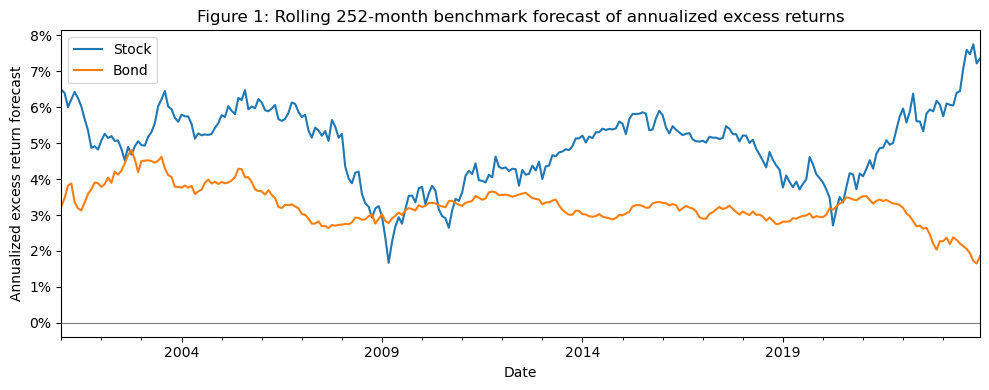

In [13]:
# Benchmark forecasts, annualized (x12) for readability
fig, ax = plt.subplots(figsize = (10, 4))
(bench * 12).plot(ax = ax)

ax.set_title("Figure 1: Rolling 252-month benchmark forecast of annualized excess returns")
ax.set_ylabel("Annualized excess return forecast")
ax.set_xlabel("Date")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.axhline(0, color = "grey", linewidth = 0.8)
ax.legend(["Stock", "Bond"])
plt.tight_layout()
plt.show()

**Figure 1** shows the out-of-sample benchmark forecasts, annualized (x 12). For each month *t* from Jan 2001 to Dec 2023, the forecast is the mean of the **actual** excess returns over the previous 252 months (*t - 252* to *t - 1*). It is a one-step-ahead forecast that only uses information available at the time, so there is no look-ahead bias. The checks above confirm this.

**Why a 252-month rolling window:** 252 months is the full in-sample period (Jan 1980 - Dec 2000), so the first forecast uses all in-sample data. The window is long enough to estimate a mean from noisy monthly returns, while dropping old observations lets the forecast adapt to changing market conditions. The same window is used in A3 and A4, so all forecasts are based on the same amount of information.

**Stocks:** the forecast starts at 6.5% a year (Jan 2001), falls to a low of 1.7% in Mar 2009 as the 2008 - 2009 crisis enters the window, and recovers to a high of 7.8% in Oct 2023.

**Bonds:** the forecast peaks at 4.8% in Oct 2002, stays around 3% between 2008 and 2021, then drops to a low of 1.7% in Nov 2023 as the 2022 bond sell-off (about -15% excess return) enters the window.

Both forecasts stay positive throughout. Because each one is an average of 252 months, they move slowly, so the benchmark is a stable but unresponsive forecast. The predictive models in A3 are tested against it.